# 위고비 MVP 가입연령 검토

대표상품 **조제당 10만 원·최대 13회·대기기간 90일**에서 보험나이와 성별에 따른 보험료·기대급부·사망을 비교한다. 기본 12개월 중단률 49% 결과와 연령군별 중단률을 적용한 탐색 결과를 분리한다.

> 판매 구조는 보험나이 19~69세 10년형과 70~74세 5년형이다. 75세 이상은 가입할 수 없으며 명시적 연구 계산만 허용한다. 판매 후보 보험료는 목표이익률 10%를 사용한다.

## 1. 라이브러리와 결과 불러오기

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown

def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate/'config/issue_age_rules.json').exists():
            return candidate
    raise FileNotFoundError('저장소 루트를 찾지 못했습니다: config/issue_age_rules.json 필요')

ROOT = find_repo_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

font_candidates = [
    Path('/System/Library/Fonts/Supplemental/Arial Unicode.ttf'),
    Path('/System/Library/Fonts/AppleSDGothicNeo.ttc'),
    Path('/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc'),
]
for font_path in font_candidates:
    if font_path.exists():
        font_manager.fontManager.addfont(str(font_path))
        plt.rcParams['font.family'] = font_manager.FontProperties(fname=font_path).get_name()
        break
plt.rcParams.update({
    'axes.unicode_minus': False,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 110,
})
BLUE, ORANGE, GREY = '#2F6B9A', '#D96C20', '#747C84'
LIGHT_BLUE, LIGHT_ORANGE = '#9CC3DF', '#F2AD68'

In [2]:
paths = {
    'mvp': ROOT/'data/derived/mvp_product_options_summary.csv',
    'baseline': ROOT/'data/derived/issue_age_baseline_results.csv',
    'exploratory': ROOT/'data/derived/issue_age_discontinuation_exploratory_results.csv',
    'senior': ROOT/'data/derived/senior_extension_5year_results.csv',
}
missing = [str(path.relative_to(ROOT)) for path in paths.values() if not path.exists()]
if missing:
    raise FileNotFoundError(
        '가입연령 결과가 없습니다. 저장소 루트에서 '
        '`python -m models.rider.mvp_age_analysis`를 먼저 실행하세요. 누락: '
        + ', '.join(missing)
    )

mvp = pd.read_csv(paths['mvp'], encoding='utf-8-sig')
baseline = pd.read_csv(paths['baseline'], encoding='utf-8-sig')
exploratory = pd.read_csv(paths['exploratory'], encoding='utf-8-sig')
senior = pd.read_csv(paths['senior'], encoding='utf-8-sig')
rules = json.loads((ROOT/'config/issue_age_rules.json').read_text(encoding='utf-8'))

assert len(mvp) == 8
assert len(baseline) == len(exploratory) == 28
assert len(senior) == 80
assert set(baseline['issue_age']) == set(rules['evaluation_issue_ages'])
assert set(baseline['sex']) == set(senior['sex']) == {'여','남'}
assert set(senior['target_profit_margin']) == {0.10}
assert set(senior['term_years']) == {5}
display(Markdown(
    f"MVP **{len(mvp)}개**, 기본 연령 결과 **{len(baseline)}행**, "
    f"연령별 중단 탐색 **{len(exploratory)}행**, 고령 확장형 **{len(senior)}행**을 불러왔다."
))

MVP **8개**, 기본 연령 결과 **28행**, 연령별 중단 탐색 **28행**, 고령 확장형 **80행**을 불러왔다.

## 2. 확정 가입연령 규칙

In [3]:
from models.rider.issue_age import validate_issue_age

policy_rows = [
    validate_issue_age(69, 10, mode='standard', rules=rules),
    validate_issue_age(74, 5, mode='senior_extension', rules=rules),
    validate_issue_age(79, 1, mode='research', rules=rules),
]
policy = pd.DataFrame(policy_rows).rename(columns={
    'mode':'구분','issue_age':'가입연령','term_years':'보험기간',
    'attained_age':'계산상 종료연령','policy_eligible':'판매 가능','status':'정책 상태'
})
display(policy)

,구분,가입연령,보험기간,계산상 종료연령,판매 가능,정책 상태
0,standard,69,10,79,True,standard_mvp
1,senior_extension,74,5,79,True,senior_extension_5year
2,research,79,1,80,False,research_only_not_for_sale


69세·10년형과 74세·5년형은 모두 79세에 종료되는 판매 후보이다. 70~74세는 정확히 5년형만 허용한다. 79세 행은 연구 계산 기능을 보여줄 뿐 판매 허용이나 상품 제안이 아니다.

## 3. 성별·연령별 대표 보험료

In [4]:
base10 = baseline[np.isclose(baseline['target_profit_margin'], .10)].copy()
premium_table = base10.pivot_table(
    index='issue_age', columns='sex', values='monthly_gross_premium_rounded_up_krw', aggfunc='first'
).reset_index().rename(columns={'issue_age':'가입연령','여':'여성','남':'남성'})
display(premium_table.style.format({'여성':'{:,.0f}원','남성':'{:,.0f}원'}))

sex,가입연령,남성,여성
0,19,"3,140원","3,140원"
1,29,"3,140원","3,140원"
2,44,"3,141원","3,140원"
3,59,"3,143원","3,141원"
4,60,"3,143원","3,141원"
5,64,"3,144원","3,142원"
6,69,"3,148원","3,143원"


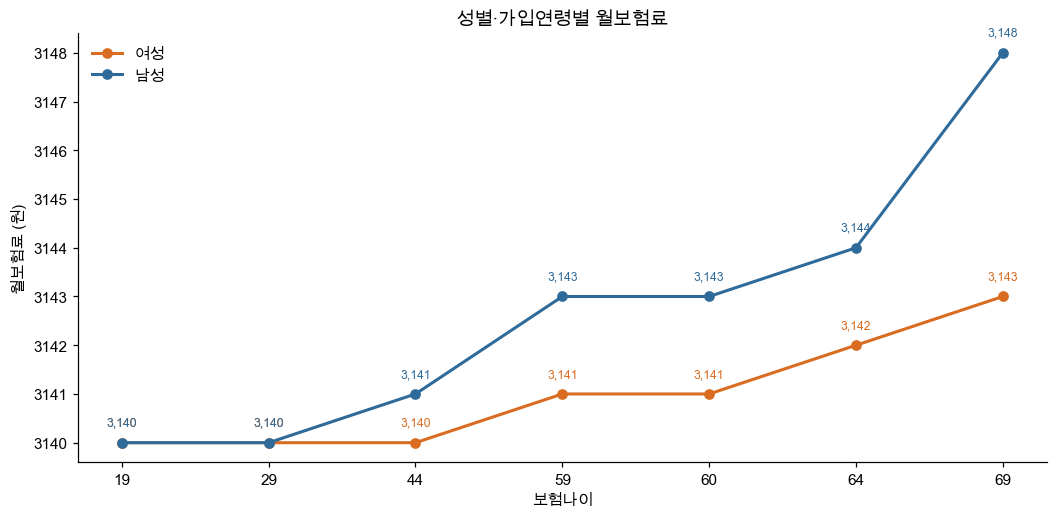

In [5]:
ages = sorted(base10['issue_age'].unique())
xpos = {age:i for i,age in enumerate(ages)}
fig, ax = plt.subplots(figsize=(9.5, 4.6), layout='constrained')
for sex, color in [('여', ORANGE), ('남', BLUE)]:
    sub = base10[base10['sex'].eq(sex)].sort_values('issue_age')
    ax.plot([xpos[x] for x in sub['issue_age']], sub['monthly_gross_premium_rounded_up_krw'],
            marker='o', lw=2, color=color, label='여성' if sex=='여' else '남성')
    for x,y in zip(sub['issue_age'],sub['monthly_gross_premium_rounded_up_krw']):
        ax.text(xpos[x],y+0.35,f'{y:,.0f}',ha='center',fontsize=8,color=color)
ax.set(title='성별·가입연령별 월보험료', xlabel='보험나이', ylabel='월보험료 (원)', xticks=range(len(ages)), xticklabels=ages)
ax.legend(frameon=False)
plt.show()

기본 49% 중단률에서는 연령별 보험료 차이가 작다. 남성 고연령에서 보험료가 조금 높지만 사망 시 급부와 납입이 함께 종료되므로 사망률 상승이 보험료에 일방적으로 반영되지는 않는다.

## 4. 연령별 기대보험금과 기대 사망

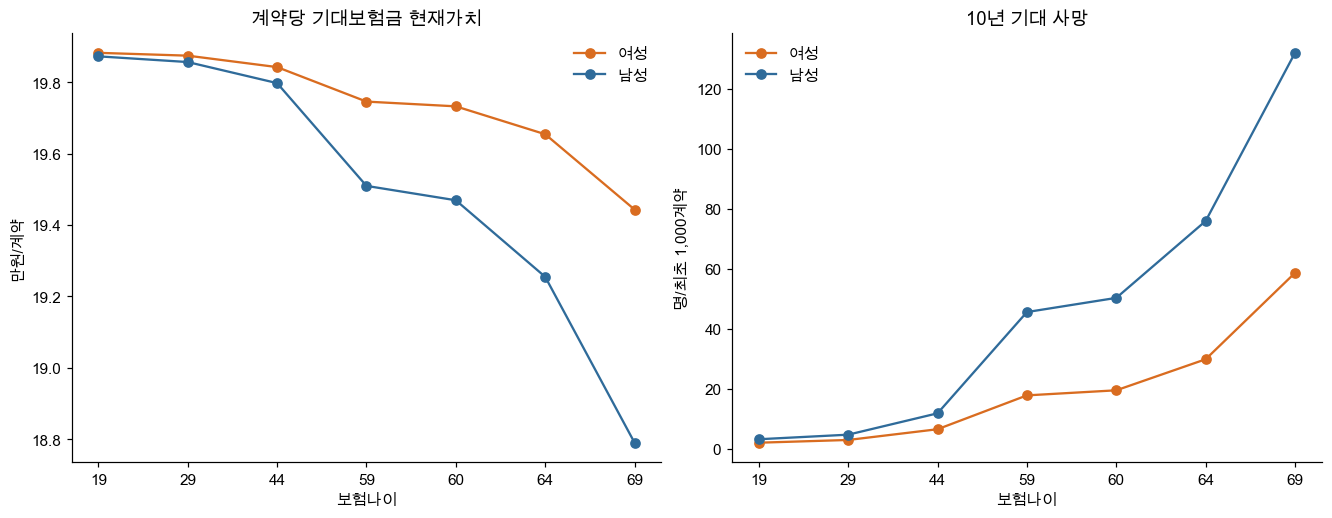

In [6]:
ages = sorted(base10['issue_age'].unique())
xpos = {age:i for i,age in enumerate(ages)}
fig, axes = plt.subplots(1,2,figsize=(12,4.6),layout='constrained')
for sex,color in [('여',ORANGE),('남',BLUE)]:
    sub=base10[base10['sex'].eq(sex)].sort_values('issue_age')
    label='여성' if sex=='여' else '남성'
    axes[0].plot([xpos[x] for x in sub['issue_age']],sub['expected_benefit_pv_per_contract_krw']/1e4,marker='o',color=color,label=label)
    axes[1].plot([xpos[x] for x in sub['issue_age']],sub['expected_deaths_per_1000_contracts'],marker='o',color=color,label=label)
axes[0].set(title='계약당 기대보험금 현재가치',xlabel='보험나이',ylabel='만원/계약',xticks=range(len(ages)),xticklabels=ages)
axes[1].set(title='10년 기대 사망',xlabel='보험나이',ylabel='명/최초 1,000계약',xticks=range(len(ages)),xticklabels=ages)
for ax in axes: ax.legend(frameon=False)
plt.show()

기대 사망은 연령과 성별 사망률에 따라 크게 증가한다. 반면 기대보험금은 사망으로 계약이 먼저 종료되는 효과 때문에 고연령에서 감소하며, 이 결과는 사망보험금이 아니라 약제비 특약 지급액이다.

## 5. 기본 모형과 연령별 중단률 탐색 비교

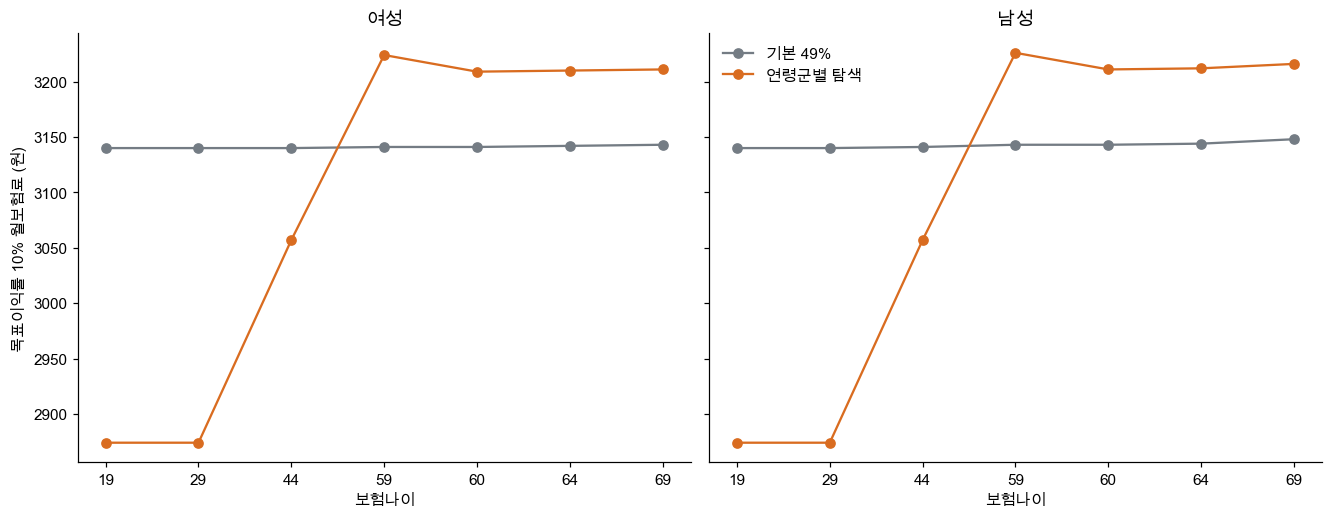

In [7]:
explore10 = exploratory[np.isclose(exploratory['target_profit_margin'], .10)]
compare = base10.merge(explore10,on=['issue_age','sex','target_profit_margin'],suffixes=('_기본','_연령탐색'))
ages = sorted(compare['issue_age'].unique())
xpos = {age:i for i,age in enumerate(ages)}
fig, axes = plt.subplots(1,2,figsize=(12,4.6),layout='constrained',sharey=True)
for ax,(sex,label) in zip(axes,[('여','여성'),('남','남성')]):
    sub=compare[compare['sex'].eq(sex)].sort_values('issue_age')
    ax.plot([xpos[x] for x in sub['issue_age']],sub['monthly_gross_premium_rounded_up_krw_기본'],marker='o',color=GREY,label='기본 49%')
    ax.plot([xpos[x] for x in sub['issue_age']],sub['monthly_gross_premium_rounded_up_krw_연령탐색'],marker='o',color=ORANGE,label='연령군별 탐색')
    ax.set(title=label,xlabel='보험나이',xticks=range(len(ages)),xticklabels=ages)
axes[0].set_ylabel('목표이익률 10% 월보험료 (원)')
axes[1].legend(frameon=False)
plt.show()

In [8]:
comparison_table = compare[[
    'issue_age','sex','annual_discontinuation_probability_연령탐색',
    'monthly_gross_premium_rounded_up_krw_기본',
    'monthly_gross_premium_rounded_up_krw_연령탐색',
    'expected_benefit_pv_per_contract_krw_기본',
    'expected_benefit_pv_per_contract_krw_연령탐색',
]].rename(columns={
    'issue_age':'가입연령','sex':'성별',
    'annual_discontinuation_probability_연령탐색':'연령군 중단률',
    'monthly_gross_premium_rounded_up_krw_기본':'기본 보험료',
    'monthly_gross_premium_rounded_up_krw_연령탐색':'탐색 보험료',
    'expected_benefit_pv_per_contract_krw_기본':'기본 기대급부 PV',
    'expected_benefit_pv_per_contract_krw_연령탐색':'탐색 기대급부 PV',
})
display(comparison_table.style.format({
    '연령군 중단률':'{:.1%}','기본 보험료':'{:,.0f}원','탐색 보험료':'{:,.0f}원',
    '기본 기대급부 PV':'{:,.0f}원','탐색 기대급부 PV':'{:,.0f}원'
}))

,가입연령,성별,연령군 중단률,기본 보험료,탐색 보험료,기본 기대급부 PV,탐색 기대급부 PV
0,19,여,64.8%,"3,140원","2,874원","198,826원","179,651원"
1,19,남,64.8%,"3,140원","2,874원","198,727원","179,562원"
2,29,여,64.8%,"3,140원","2,874원","198,746원","179,580원"
3,29,남,64.8%,"3,140원","2,874원","198,568원","179,418원"
4,44,여,54.2%,"3,140원","3,057원","198,426원","192,511원"
5,44,남,54.2%,"3,141원","3,057원","197,977원","192,076원"
6,59,여,43.6%,"3,141원","3,224원","197,459원","203,262원"
7,59,남,43.6%,"3,143원","3,226원","195,097원","200,830원"
8,60,여,44.6%,"3,141원","3,209원","197,326원","202,073원"
9,60,남,44.6%,"3,143원","3,211원","194,695원","199,377원"


19~29세 탐색 중단률 64.8%는 기본 49%보다 높아 기대 지급과 보험료가 낮아진다. 45세 이상은 연령군 중단률이 기본보다 낮아 기대 지급과 보험료가 높아진다. 이는 관측 평균을 이용한 탐색 결과이며 실제 연령별 시작률·재개율·해지율을 추정한 값은 아니다.

## 6. 70~74세 5년형 확장상품 검토

10년형을 70세 이상에 적용하면 최대 보장종료연령 79세를 넘는다. 고령 확장형은 상품별 시작률 경로를 실제 5주년 전일까지 제한해 시작·납입·급부·사업비를 다시 계산했다.

In [9]:
representative_senior = senior[senior['product_id'].eq('benefit100k_max13_wait90')]
senior_premium_table = representative_senior.pivot_table(
    index='issue_age', columns='sex', values='monthly_gross_premium_rounded_up_krw', aggfunc='first'
).reset_index().rename(columns={'issue_age':'가입연령','여':'여성','남':'남성'})
display(Markdown('**대표상품 5년형 월보험료 — 목표이익률 10%**'))
display(senior_premium_table.style.format({'여성':'{:,.0f}원','남성':'{:,.0f}원'}))

senior = senior.assign(
    상품=senior['benefit_per_dispense_krw'].div(10000).astype(int).astype(str)+'만×'
        +senior['max_claims'].astype(int).astype(str)+'회×'
        +senior['waiting_days'].astype(int).astype(str)+'일'
)
design_ranges = senior.groupby('상품', sort=False).agg(
    보험료_최저=('monthly_gross_premium_rounded_up_krw','min'),
    보험료_최고=('monthly_gross_premium_rounded_up_krw','max'),
    지원반응_NPV_최저=('response_high_npv_per_1000_contracts_krw','min'),
    지원반응_NPV_최고=('response_high_npv_per_1000_contracts_krw','max'),
    시작률복합_NPV_최저=('start_combined_stress_npv_per_1000_contracts_krw','min'),
    시작률복합_NPV_최고=('start_combined_stress_npv_per_1000_contracts_krw','max'),
    치료행태_NPV_최저=('treatment_combined_stress_npv_per_1000_contracts_krw','min'),
    치료행태_NPV_최고=('treatment_combined_stress_npv_per_1000_contracts_krw','max'),
).reset_index()
npv_cols = [c for c in design_ranges if 'NPV' in c]
design_ranges[npv_cols] = design_ranges[npv_cols] / 1e4
display(Markdown('**8개 상품의 보험료·스트레스 NPV 범위 — 최초 1,000계약, 만 원**'))
display(design_ranges.style.format({
    '보험료_최저':'{:,.0f}원','보험료_최고':'{:,.0f}원',
    **{c:'{:+,.0f}' for c in npv_cols}
}))

**대표상품 5년형 월보험료 — 목표이익률 10%**

sex,가입연령,남성,여성
0,70,"3,294원","3,290원"
1,71,"3,294원","3,291원"
2,72,"3,295원","3,291원"
3,73,"3,296원","3,292원"
4,74,"3,297원","3,292원"


**8개 상품의 보험료·스트레스 NPV 범위 — 최초 1,000계약, 만 원**

,상품,보험료_최저,보험료_최고,지원반응_NPV_최저,지원반응_NPV_최고,시작률복합_NPV_최저,시작률복합_NPV_최고,치료행태_NPV_최저,치료행태_NPV_최고
0,10만×6회×30일,"2,218원","2,229원",+888,+910,"-2,123","-2,046",+968,+993
1,10만×6회×90일,"2,212원","2,223원",+888,+909,"-2,110","-2,032",+959,+982
2,10만×13회×30일,"3,302원","3,309원",+628,+642,"-5,030","-4,853",+923,+945
3,10만×13회×90일,"3,290원","3,297원",+638,+653,"-4,990","-4,809",+905,+927
4,15만×6회×30일,"2,900원","2,911원",+889,+911,"-3,701","-3,575","+1,229","+1,262"
5,15만×6회×90일,"2,891원","2,902원",+889,+910,"-3,681","-3,552","+1,215","+1,247"
6,15만×13회×30일,"4,552원","4,558원",-361,-339,"-9,342","-9,017","+1,168","+1,196"
7,15만×13회×90일,"4,534원","4,539원",-331,-309,"-9,254","-8,930","+1,139","+1,167"


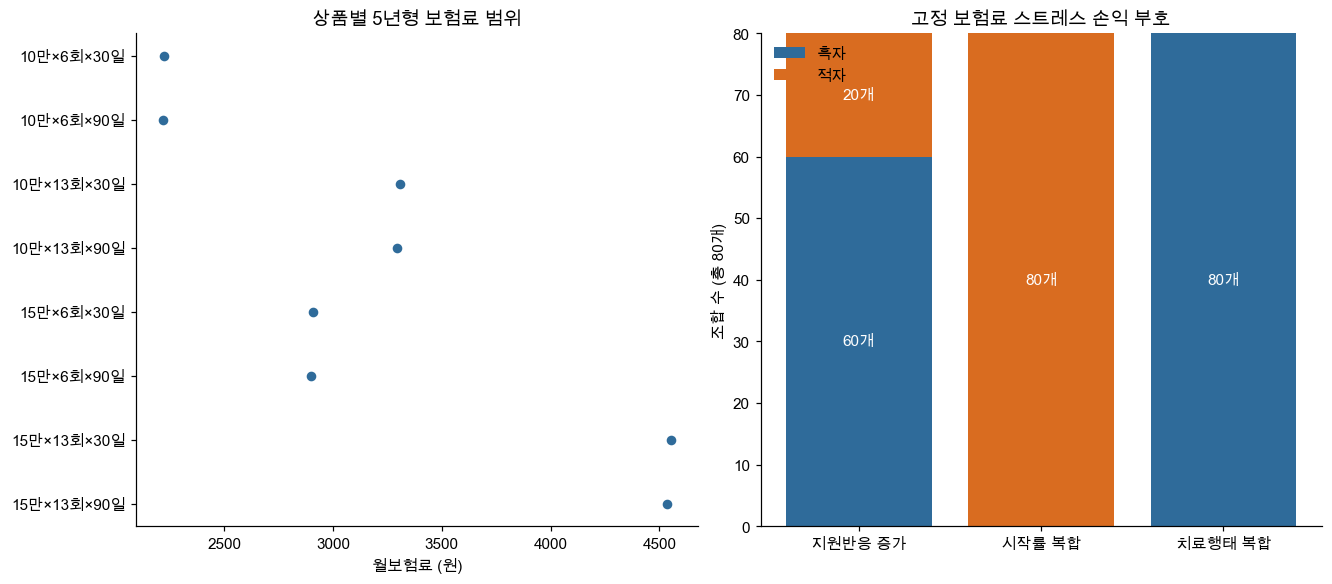

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), layout='constrained')

y = np.arange(len(design_ranges))
low = design_ranges['보험료_최저'].to_numpy()
high = design_ranges['보험료_최고'].to_numpy()
axes[0].hlines(y, low, high, color=LIGHT_BLUE, linewidth=6)
axes[0].scatter((low+high)/2, y, color=BLUE, s=28, zorder=3)
axes[0].set(yticks=y, yticklabels=design_ranges['상품'], xlabel='월보험료 (원)', title='상품별 5년형 보험료 범위')
axes[0].invert_yaxis()

stress_columns = {
    '지원반응 증가':'response_high_npv_per_1000_contracts_krw',
    '시작률 복합':'start_combined_stress_npv_per_1000_contracts_krw',
    '치료행태 복합':'treatment_combined_stress_npv_per_1000_contracts_krw',
}
loss = [(senior[col] < 0).sum() for col in stress_columns.values()]
profit = [len(senior)-x for x in loss]
x = np.arange(3)
axes[1].bar(x, profit, color=BLUE, label='흑자')
axes[1].bar(x, loss, bottom=profit, color=ORANGE, label='적자')
for i, (p, l) in enumerate(zip(profit, loss)):
    if p:
        axes[1].text(i, p/2, f'{p}개', ha='center', va='center', color='white', fontweight='bold')
    if l:
        axes[1].text(i, p+l/2, f'{l}개', ha='center', va='center', color='white', fontweight='bold')
axes[1].set(xticks=x, xticklabels=list(stress_columns), ylabel='조합 수 (총 80개)', title='고정 보험료 스트레스 손익 부호')
axes[1].legend(frameon=False, loc='upper left')
plt.show()

대표상품 보험료는 여성 3,290~3,292원, 남성 3,294~3,297원이다. 전체 8개 상품은 2,212~4,558원 범위다. 치료행태 복합 스트레스는 80개 모두 흑자지만 시작률 복합 스트레스는 모두 적자다. 지원반응 증가의 적자 20개는 모두 15만 원×13회 상품이며, 이는 고령 확장형에서도 같은 주의가 필요함을 보여준다.

## 7. 결론

- 보험나이 **19~69세는 10년형**, **70~74세는 5년형**으로 판매 후보를 구분하며 두 상품 모두 최대 79세에 종료한다.
- 75세 이상은 가입할 수 없고 명시적 연구 계산만 허용한다.
- 판매 후보 보험료는 목표이익률 **10%**로 확정한다. 0%·5% 결과는 연구 비교와 회귀검증용으로만 보존한다.
- 기본 가격은 전체 12개월 중단률 49%를 유지한다. 연령별 중단률은 별도 탐색 결과로만 사용한다.
- 기준 NPV는 각 가정에 맞춰 보험료를 재산출한 결과이므로 독립적인 수익성 증명이 아니다.